In [1]:
import numpy as np
import pandas as pd

import sxs
path_to_codes = '/home/samanwaya/gwfit/gwfit/'
import sys
sys.path.append(path_to_codes)
import useful_relations as urel
import constants as const
import nr_data_utils as nr

import h5py as h5
import json
import matplotlib.pyplot as plt

In [2]:
sxs.sxs_directory("config")
sxs.write_config(download=True, cache=True, auto_supersede=True)
sxs.read_config()
sxs.sxs_directory("cache")

PosixPath('/home/samanwaya/.cache/sxs')

In [3]:
simulations = sxs.load("simulations")

df = simulations.dataframe

# Nonspinning BBHs
df_filtered = nr.filter_simulations(
    df,
    q=(3,None),
    chi1=(0, 1e-4),
    chi2=(0, 1e-4),
)

Loading SXS simulations using latest tag 'v3.0.0', published at 2025-05-14T18:17:30Z.


In [4]:
# df_filtered_short = df_filtered[[
#             "reference_time",
#             "reference_mass_ratio",
#             "reference_dimensionless_spin1",
#             "reference_dimensionless_spin2",
#             "number_of_orbits",
#             "reference_eccentricity"
#           ]]  # specify which entries you want to show on the dataframe

df_filtered_sorted = df_filtered.sort_values("reference_mass_ratio") #sorted by increasing mass ratio

nonspinning_circular_labels = df_filtered_sorted.index.to_numpy(dtype=str)
print(len(nonspinning_circular_labels))
print(nonspinning_circular_labels)

19
['SXS:BBH:2265' 'SXS:BBH:2483' 'SXS:BBH:2484' 'SXS:BBH:3144'
 'SXS:BBH:2487' 'SXS:BBH:3619' 'SXS:BBH:2486' 'SXS:BBH:2489'
 'SXS:BBH:2488' 'SXS:BBH:2491' 'SXS:BBH:2490' 'SXS:BBH:2493'
 'SXS:BBH:2707' 'SXS:BBH:2492' 'SXS:BBH:2495' 'SXS:BBH:1108'
 'SXS:BBH:2494' 'SXS:BBH:2480' 'SXS:BBH:2477']


SXS:BBH:2265 3.000112224984311
SXS:BBH:2483 3.499942504651751
SXS:BBH:2484 4.4995631767635835
SXS:BBH:3144 4.499621846563142
SXS:BBH:2487 4.999936029137081
SXS:BBH:3619 5.000307275688211
SXS:BBH:2486 5.50003563689487
SXS:BBH:2489 5.999531974378745
SXS:BBH:2488 6.499550871499383
SXS:BBH:2491 7.00017202109518
SXS:BBH:2490 7.49959753009933
SXS:BBH:2493 7.999879065402133
SXS:BBH:2707 8.000149200385618
SXS:BBH:2492 8.50110106507095
SXS:BBH:2495 9.000894345205925
SXS:BBH:1108 9.199933130774635
SXS:BBH:2494 9.49734337785268
SXS:BBH:2480 14.000176436745123
SXS:BBH:2477 14.999984440092447


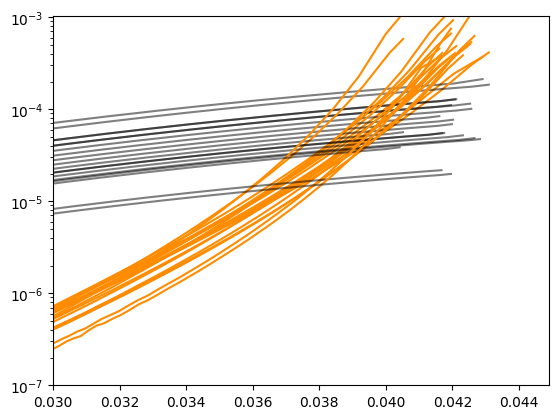

In [8]:
for sim_label in nonspinning_circular_labels:
# for sim_label in ['SXS:BBH:2480']:
    sim_prem = nr.SXSSimulation(simulation_label=sim_label,
                                    initial_cutoff='reference',
                                    final_cutoff='common_horizon',
                               )
    print(sim_label,sim_prem.metadata.reference_mass_ratio)
    
    twf, gw_freq = sim_prem.mode_frequency(mode=(2,2))
    _, gw_flux = sim_prem.gw_flux(ell_max=2)
    orb_freq = gw_freq/2.
    # plt.plot(twf,gw_freq)
    t, fA, fB = sim_prem.horizon.component_horizon_fluxes(times_to_interpolate=twf)

    dMdt = fA + fB

    mask = (
        (twf >= t[0]) &
        (twf <= t[-1])
    )

    gw_freq = gw_freq[mask]
    gw_flux = gw_flux[mask]
    
    plt.semilogy(gw_freq,dMdt,c='darkorange')
    plt.semilogy(gw_freq,gw_flux,c='k', alpha=0.5)
    plt.xlim(left=0.03)
    plt.ylim(bottom=1e-7)
plt.show()